/tmp/ipython-input-3753758052.py:18: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  5 of 5 completed
/tmp/ipython-input-3753758052.py:89: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  total_return = cumulative_returns[-1] - 1
/tmp/ipython-input-3753758052.py:112: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"Portfolio Cumulative Return: {(cumulative_returns[-1] - 1):.2%}")


Portfolio Annualized Return: 1186.57%
Portfolio Annualized Volatility: 13.30%
Portfolio Sharpe Ratio (annualized): 1.17
Portfolio Maximum Drawdown: -92.52%
Portfolio Cumulative Return: 2615136225.91%

Sample of optimized weights (Date, Weights):
2019-01-04: {'EURUSD=X': np.float64(0.9999999999999996), 'USDJPY=X': np.float64(0.0), 'GLD': np.float64(1.1102230246251565e-16), 'SPY': np.float64(8.326672684688674e-17), 'BTC-USD': np.float64(4.718447854656915e-16)}
2019-01-07: {'EURUSD=X': np.float64(1.0), 'USDJPY=X': np.float64(4.8854511258266494e-17), 'GLD': np.float64(0.0), 'SPY': np.float64(0.0), 'BTC-USD': np.float64(0.0)}
2019-01-08: {'EURUSD=X': np.float64(1.0), 'USDJPY=X': np.float64(7.163302547031535e-18), 'GLD': np.float64(0.0), 'SPY': np.float64(0.0), 'BTC-USD': np.float64(0.0)}


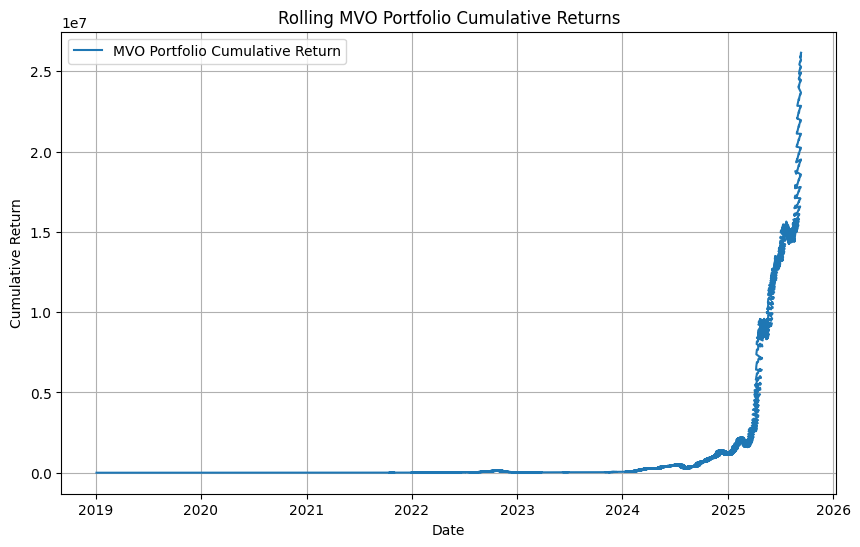

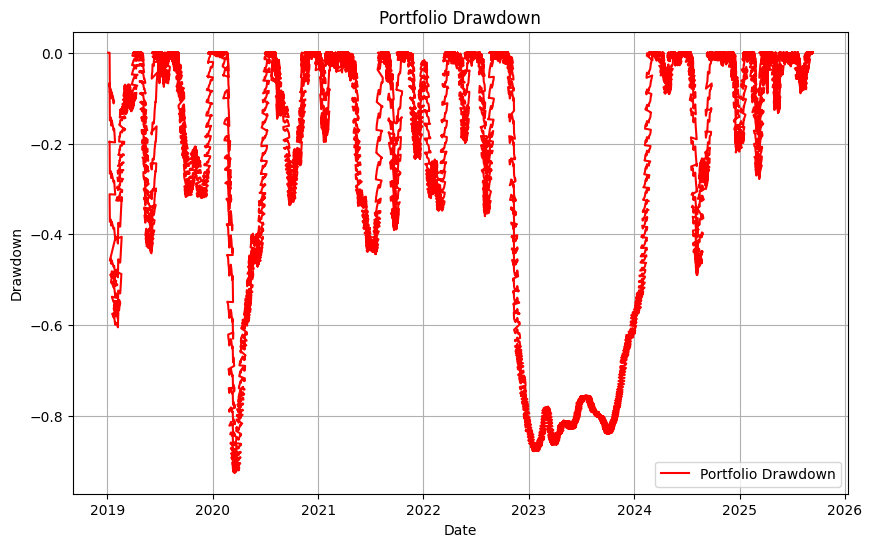

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from datetime import timedelta

# Define parameters
tickers = ['EURUSD=X', 'USDJPY=X', 'GLD', 'SPY', 'BTC-USD']  # Assets for portfolio
start_date = '2018-01-01'  # Extended start for 1-year lookback
end_date = '2025-09-12'
rolling_window = 252  # 1-year lookback (trading days)
rebalance_period = 21  # Approx 1 month (trading days)
risk_free_rate = 0.02  # Annual risk-free rate (2%)
trading_days = 252  # Trading days per year

# Download close prices
data = yf.download(tickers, start=start_date, end=end_date)['Close']
data = data.dropna()

# Calculate daily returns
daily_returns = data.pct_change().dropna()

# Function to calculate portfolio return and volatility
def portfolio_performance(weights, mean_returns, cov_matrix):
    port_return = np.sum(mean_returns * weights) * trading_days
    port_std = np.sqrt(np.dot(weights.T, np.dot(cov_matrix * trading_days, weights)))
    return port_return, port_std

# Negative Sharpe ratio to minimize
def negative_sharpe(weights, mean_returns, cov_matrix, risk_free_rate):
    port_return, port_std = portfolio_performance(weights, mean_returns, cov_matrix)
    return - (port_return - risk_free_rate) / port_std

# Constraints and bounds
def optimize_weights(mean_returns, cov_matrix):
    num_assets = len(mean_returns)
    args = (mean_returns, cov_matrix, risk_free_rate)
    constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
    bounds = tuple((0, 1) for _ in range(num_assets))
    result = minimize(negative_sharpe, num_assets * [1. / num_assets], args=args,
                     method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x if result.success else num_assets * [1. / num_assets]  # Fallback to equal weights if fails

# Backtest
portfolio_returns = []
portfolio_dates = []
optimized_weights = []
current_date = daily_returns.index[rolling_window]

while current_date < daily_returns.index[-1]:
    # Get historical data for optimization (exclude current_date to avoid look-ahead bias)
    hist_indices = daily_returns.index[daily_returns.index < current_date]
    if len(hist_indices) < rolling_window:
        break
    hist_returns = daily_returns.loc[hist_indices[-rolling_window:]]
    mean_returns = hist_returns.mean()
    cov_matrix = hist_returns.cov()

    # Optimize weights
    weights = optimize_weights(mean_returns, cov_matrix)
    optimized_weights.append((current_date, dict(zip(tickers, weights))))

    # Calculate portfolio returns for the next rebalance period (forward-looking)
    next_date = min(current_date + timedelta(days=rebalance_period), daily_returns.index[-1])
    period_indices = daily_returns.index[(daily_returns.index >= current_date) & (daily_returns.index <= next_date)]
    if len(period_indices) == 0:
        break
    period_returns = daily_returns.loc[period_indices]
    period_portfolio_returns = (period_returns * weights).sum(axis=1)

    portfolio_returns.extend(period_portfolio_returns)
    portfolio_dates.extend(period_portfolio_returns.index)

    # Move to next rebalance date
    next_candidates = daily_returns.index[daily_returns.index > current_date]
    if len(next_candidates) > 0:
        current_date = next_candidates[0]
    else:
        break

# Create portfolio returns series
portfolio_returns = pd.Series(portfolio_returns, index=portfolio_dates)

# Calculate cumulative returns
cumulative_returns = (1 + portfolio_returns).cumprod()

# Calculate annualized return
total_return = cumulative_returns[-1] - 1
days = (cumulative_returns.index[-1] - cumulative_returns.index[0]).days
years = days / 365.25
annualized_return = (1 + total_return) ** (1 / years) - 1

# Calculate annualized volatility
portfolio_volatility = portfolio_returns.std() * np.sqrt(trading_days)

# Calculate Sharpe ratio (annualized)
mean_daily_return = portfolio_returns.mean()
std_daily_return = portfolio_returns.std()
sharpe_ratio = (mean_daily_return * trading_days - risk_free_rate) / (std_daily_return * np.sqrt(trading_days))

# Calculate maximum drawdown
rolling_max = cumulative_returns.cummax()
drawdowns = (cumulative_returns - rolling_max) / rolling_max
max_drawdown = drawdowns.min()

# Print results
print(f"Portfolio Annualized Return: {annualized_return:.2%}")
print(f"Portfolio Annualized Volatility: {portfolio_volatility:.2%}")
print(f"Portfolio Sharpe Ratio (annualized): {sharpe_ratio:.2f}")
print(f"Portfolio Maximum Drawdown: {max_drawdown:.2%}")
print(f"Portfolio Cumulative Return: {(cumulative_returns[-1] - 1):.2%}")
print("\nSample of optimized weights (Date, Weights):")
for date, wts in optimized_weights[:3]:  # Show first 3 rebalances
    print(f"{date.date()}: {wts}")

# Plot cumulative returns
plt.figure(figsize=(10, 6))
plt.plot(cumulative_returns.index, cumulative_returns, label='MVO Portfolio Cumulative Return')
plt.title('Rolling MVO Portfolio Cumulative Returns')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.grid(True)
plt.legend()
plt.show()

# Plot drawdowns
plt.figure(figsize=(10, 6))
plt.plot(drawdowns.index, drawdowns, label='Portfolio Drawdown', color='red')
plt.title('Portfolio Drawdown')
plt.xlabel('Date')
plt.ylabel('Drawdown')
plt.grid(True)
plt.legend()
plt.show()